# Aprendizaje supervisado

En este cuaderno veremos cómo entrenar diferentes algoritmos de aprendizaje automático utilizando sklearn. Esta librería contiene multitud de modelos y funcionalidades implementadas para *machine learning*, por lo que podremos usar sus módulos sin necesidad de tener que implementar nada nosotros.

## 1. Cargar conjuntos de datos

El primer paso es cargar los conjuntos de datos. Utilizaremos datasets de ejemplo disponibles en sklearn, tanto para clasificación como para regresión.

Para el ejemplo de **regresión**, utilizaremos el California Housing dataset. El objetivo es predecir el precio de una casa (expresado en cientos de miles de $), utilizando para ello información como su antigüedad, número de habitaciones, localización, etc.

In [2]:
from sklearn import datasets

# Cargamos el conjunto de datos para regresión
data_reg, target_reg = datasets.fetch_california_housing(as_frame=True, return_X_y=True)

print(f"Dimensión del dataset: {data_reg.shape}")
data_reg.head()

Dimensión del dataset: (20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


<AxesSubplot:>

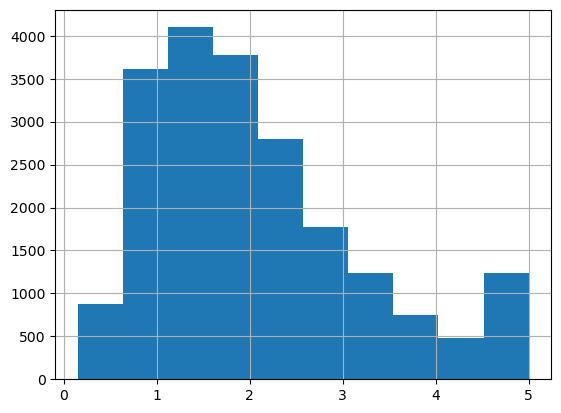

In [ ]:
target_reg.hist()

Para el ejemplo de **clasificación**, utilizaremos el Breast Cancer dataset. El objetivo aquí es identificar si un tumor es benigno (target = 1) o no (target = 0), a partir de variables de sus células como el radio, area, simetría, etc.

In [3]:
# Cargamos el dataset para clasificación
data_clas, target_clas = datasets.load_breast_cancer(as_frame=True, return_X_y=True)

print(f"Dimensión del dataset: {data_clas.shape}")
data_clas.head()

Dimensión del dataset: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
target_clas.value_counts()

,count
target,
1,357
0,212


Antes de empezar a entrenar modelos, vamos a separar los conjuntos de datos en dos: un conjunto de entrenamiento para ajustar los algoritmos, y otro conjunto de test para medir el rendimiento y su capacidad de generalización.

Para regresión, utilizamos una proporción 70/30. El parámetro `random_state` nos servirá para garantizar la reproducibilidad de los resultados.

In [5]:
# Separamos en train/test
from sklearn.model_selection import train_test_split

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    data_reg, target_reg, test_size = 0.3, random_state = 42
)

print(X_reg_train.shape, X_reg_test.shape)

(14448, 8) (6192, 8)


Para clasificación, usamos la proporción 80/20. Definimos la opción de `stratify` para que cada conjunto tenga la misma proporción de clases.

In [6]:
X_clas_train, X_clas_test, y_clas_train, y_clas_test = train_test_split(
    data_clas, target_clas, test_size = 0.2, stratify=target_clas, random_state = 42
)

print(X_clas_train.shape, X_clas_test.shape)

(455, 30) (114, 30)


Tras esto, ahora ya sí podemos empezar a modelizar! Comencemos con el problema de regresión utilizando la regresión lineal.

## 2. Regresión lineal

Como hemos visto, el modelo más sencillo de regresión es la regresión lineal. Entrenar este algoritmo solo requiere 3 líneas de código en sklearn.

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_reg_train, y_reg_train)

LinearRegression()

Y voilá! Ya tenemos el modelo entrenado. Podemos ver los valores resultantes de los coeficientes y del término independiente.

In [ ]:
print('Término independiente: ', lr.intercept_)

for name, value in zip(lr.feature_names_in_, lr.coef_):
    print('Variable %s, coeficiente: %.3f' % (name, value))

Término independiente:  -37.05624133152507
Variable MedInc, coeficiente: 0.446
Variable HouseAge, coeficiente: 0.010
Variable AveRooms, coeficiente: -0.122
Variable AveBedrms, coeficiente: 0.779
Variable Population, coeficiente: -0.000
Variable AveOccup, coeficiente: -0.003
Variable Latitude, coeficiente: -0.419
Variable Longitude, coeficiente: -0.434


Cada coeficiente nos indica cómo varía el target al aumentar cada una de las variables de entrada.

sklearn también nos devuelve automáticamente una métrica de evaluación con el método `score`, en este caso el coeficiente de determinación R2. Utilicémoslo para calcular el error en el conjunto de entrenamiento.

In [ ]:
print('R2 en training: ', lr.score(X_reg_train, y_reg_train))

R2 en training:  0.6093459727972159


Pero sabemos que donde realmente necesitamos evaluarlo es en el conjunto de test:

In [ ]:
print('R2 en test: ', lr.score(X_reg_test, y_reg_test))

R2 en test:  0.5957702326061665


Vemos que obtenemos un R2 de 0.61 en el conjunto de entrenamiento y de 0.60 en el conjunto de test. No es brillante, pero no está mal para una regresión lineal sencilla!

Para conseguir las predicciones del modelo, utilizamos el método `predict`.

In [ ]:
# Predicciones sobre el conjunto de test
preds_reg = lr.predict(X_reg_test)

print('Primeras 5 predicciones: ', preds_reg[:5])
print('Targets reales: ', y_reg_test.values[:5])

Primeras 5 predicciones:  [0.72604907 1.76743383 2.71092161 2.83514727 2.60695807]
Targets reales:  [0.477   0.458   5.00001 2.186   2.78   ]


Las predicciones no son perfectas, y en ocasiones el modelo comete errores bastante grandes.

Para cuantificar estas diferencias, vamos a calcular algunas métricas adicionales utilizando el módulo `metrics` de sklearn.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# Calculamos el MAE y el MAPE en el conjunto de test
mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)

MAE en test: 0.527
MAPE en test: 0.318


El error absoluto medio es 0.53, mientras que el porcentual es del 32%. Veremos cómo utilizando modelos más complejos podemos obtener resultados mejores.

Para finalizar, vamos a visualizar la distribución de los residuos en el conjunto de test. Como se puede ver el modelo tiende a sobrestimar ligeralmente para valores pequeños del target, mientras que para valores grandes subestima más.

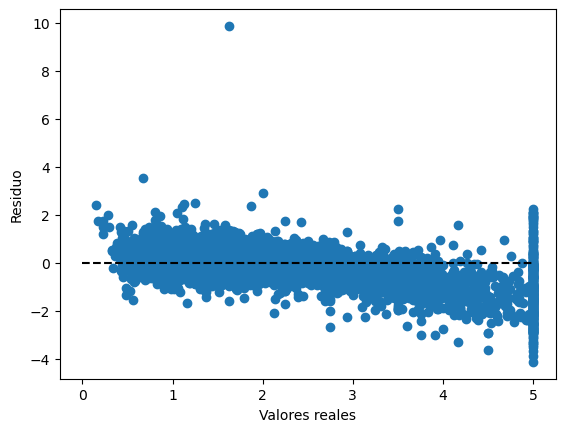

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

residuals = preds_reg - y_reg_test

plt.scatter(y_reg_test, residuals)
plt.hlines(0, xmin=0, xmax=5, linestyles='--', color='k')
plt.xlabel('Valores reales')
plt.ylabel('Residuo')
plt.show()

## 3. Regresión logística

Pasemos ahora al problema de clasificación binario, donde comenzaremos utilizando la regresión logística. Nuevamente, entrenar el modelo es casi inmediato en sklearn.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Creamos el modelo especificando el tipo de solver numérico (es opcional), fijando la semilla para evitar aleatoriedad
logreg = LogisticRegression(random_state=42, solver='liblinear')

# Entrenamos con el conjunto de train y su target
logreg.fit(X_clas_train, y_clas_train)

LogisticRegression(random_state=42, solver='liblinear')

Veamos el desempeño del modelo en el conjunto de test, utilizando como métrica la tasa de acierto.

In [ ]:
print('Accuracy en train: ', logreg.score(X_clas_train, y_clas_train))
print('Accuracy en test: ', logreg.score(X_clas_test, y_clas_test))

Accuracy en train:  0.9560439560439561
Accuracy en test:  0.9649122807017544


¡Obtenemos un 96% de acierto en ambos conjuntos! Es un buen resultado, y además vemos que no tenemos sobreajuste.

Para obtener las predicciones en modelos de clasificación podemos usar tanto el método `predict`, obteniendo la categoría estimada, como `predict_proba` para obtener las probabilidades de cada clase.

In [ ]:
preds_clas = logreg.predict(X_clas_test)
probs_clas = logreg.predict_proba(X_clas_test)

print(y_clas_test[:5])
print(probs_clas[:5])

256    0
428    1
501    0
363    1
564    0
Name: target, dtype: int64
[[1.00000000e+00 9.84826330e-13]
 [3.47052696e-04 9.99652947e-01]
 [8.98297445e-01 1.01702555e-01]
 [3.41003136e-01 6.58996864e-01]
 [1.00000000e+00 2.36245829e-12]]


Nótese que cada predicción de probabilidades está compuesta por dos números: el primero indica la probabilidad de la clase 0 (maligno) y el segundo la probabilidad de la clase 1 (benigno).

Calculemos ahora otras métricas para cuantificar el rendimiento del modelo en el conjunto de test. Todas ellas se calculan con las clases predichas.

In [ ]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

# Calculamos las métricas globales, con el parámetro average
precision = precision_score(y_clas_test, preds_clas)
recall = recall_score(y_clas_test, preds_clas)
cm = confusion_matrix(y_clas_test, preds_clas)

print('Precision: %.3f' % precision)
print('Recall %.3f' % recall)
print(cm)

Precision: 0.972
Recall 0.972
[[40  2]
 [ 2 70]]


Vemos que en este caso el modelo es casi perfecto, con una precisión y un recall por encima de 0.97. Además, la matriz de confusión nos indica que solo se cometen 4 errores en el conjunto de test: 2 falsos positivos y 2 falsos negativos.

Para finalizar, dibujemos la curva ROC y extraigamos su AUC. Para ello, utilizamos la probabilidad de la clase positiva.

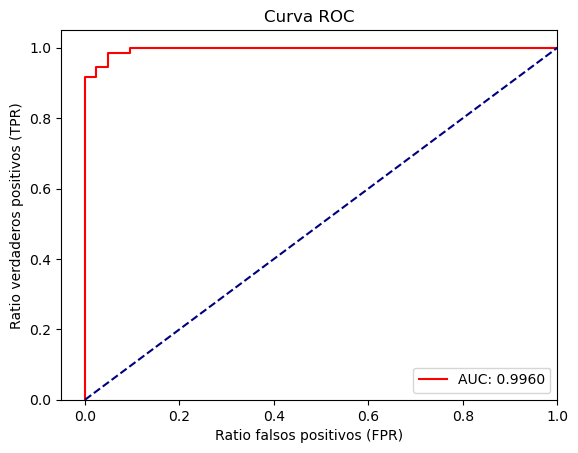

In [ ]:
from sklearn.metrics import roc_curve, auc

# Datos para la curva ROC
probs_pos = probs_clas[:,1]
fpr, tpr, thresholds = roc_curve(y_clas_test, probs_pos)

# Calculamos el AUC
auc = auc(fpr, tpr)

# Dibujamos la curva
plt.plot(fpr, tpr, label = 'AUC: %.4f' % auc, color = 'red')
plt.plot([0, 1], [0, 1], color="navy", linestyle="--") # Línea referencia para modelo aleatorio
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Ratio falsos positivos (FPR)")
plt.ylabel("Ratio verdaderos positivos (TPR)")
plt.title("Curva ROC")
plt.legend()
plt.show()

La curva ROC es casi perfecta, con un AUC muy próxima a 1. Este resultado se debe a que el dataset es sencillo, en problemas reales consideramos un buen resultado un AUC superior a 0.7 ó 0.8. [Aquí](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html#sphx-glr-auto-examples-model-selection-plot-roc-py) se puede ver un ejemplo también para visualizar curvas ROC en el caso multi-clase.

Recuerda que el AUC es independiente del punto de corte elegido, mientras que la tasa de acierto o la precisión sí dependen de ella. ¿Cómo podemos elegir un punto de corte adecuado?

Una forma de hacerlo es probar diferentes puntos de corte, y calcular esas métricas. Por ejemplo, un punto de corte de 0.1 indicará que todos los registros cuya probabilidad estimada sea superior a 0.1, se clasificarán como positivos. En la celda siguiente se calculan la precisión y el recall para diferentes puntos de corte, y se representa gráficamente.

Punto de corte 0.01 | Precisión: 0.889, Recall: 1.000
Punto de corte 0.05 | Precisión: 0.911, Recall: 1.000
Punto de corte 0.10 | Precisión: 0.911, Recall: 1.000
Punto de corte 0.20 | Precisión: 0.923, Recall: 1.000
Punto de corte 0.30 | Precisión: 0.947, Recall: 0.986
Punto de corte 0.40 | Precisión: 0.947, Recall: 0.986
Punto de corte 0.50 | Precisión: 0.972, Recall: 0.972
Punto de corte 0.60 | Precisión: 0.972, Recall: 0.972
Punto de corte 0.70 | Precisión: 0.971, Recall: 0.944
Punto de corte 0.80 | Precisión: 0.986, Recall: 0.944


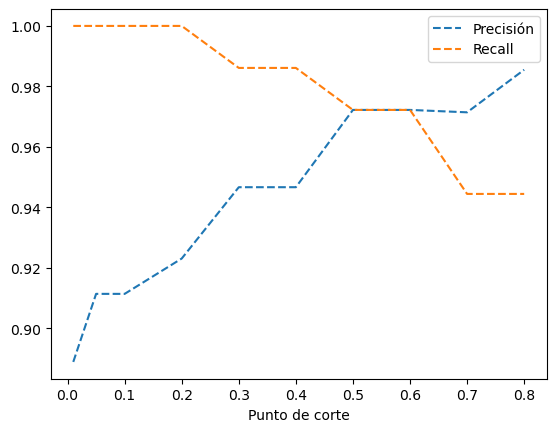

In [ ]:
import numpy as np

# Puntos de corte posibles
thresholds = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

precisions = []
recalls = []
# Probamos cada uno de ellos y calculamos sus métricas
for thr in thresholds:
    y_pred = np.where(probs_pos >= thr, 1, 0)
    precision = precision_score(y_clas_test, y_pred)
    recall = recall_score(y_clas_test, y_pred)
    precisions.append(precision)
    recalls.append(recall)

    print('Punto de corte %.2f | Precisión: %.3f, Recall: %.3f' % (thr, precision, recall))

plt.plot(thresholds, precisions, '--', label = 'Precisión')
plt.plot(thresholds, recalls, '--', label = 'Recall')
plt.xlabel('Punto de corte')
plt.legend()
plt.show()

## 4. Probando otros algoritmos

En este caso los modelos lineales han hecho un buen trabajo y se ha obtenido un resultado decente, pero en la práctica es habitual probar diferentes modelos para encontrar el que mejor rendimiento tenga. En esta sección vamos a probar 4 algoritmos diferentes para ver si funcionan mejor que los anteriores.

### a) Árbol de decisión

Empecemos con el árbol de decisión, tanto para regresión como para clasificación.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Inicializamos los árboles...
tree_class = DecisionTreeClassifier(max_depth = 3, random_state = 42)
tree_reg = DecisionTreeRegressor(random_state = 42)

# ...los entrenamos...
tree_reg.fit(X_reg_train, y_reg_train)
tree_class.fit(X_clas_train, y_clas_train)

# ...y los evaluamos en el conjunto de test
print('Regresión')
print('-'*10)

preds_reg = tree_reg.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)
print('')

print('Clasificación')
print('-'*10)

preds_clas = tree_class.predict(X_clas_test)

precision = precision_score(y_clas_test, preds_clas)
recall = recall_score(y_clas_test, preds_clas)
cm = confusion_matrix(y_clas_test, preds_clas)

print('Precision: %.3f' % precision)
print('Recall %.3f' % recall)
print(cm)

Regresión
----------
MAE en test: 0.469
MAPE en test: 0.259

Clasificación
----------
Precision: 0.945
Recall 0.958
[[38  4]
 [ 3 69]]


En este caso los árboles de decisión no parecen superar a los modelos lineales en ninguno de los dos problemas.

Una de las ventajas de los árboles es que son modelos interpretables. Así que vamos a extraer primero la importancia de las variables, por ejemplo para el problema de regresión.

In [ ]:
for var, value in zip(tree_reg.feature_names_in_, tree_reg.feature_importances_):
    print('%s: %.3f' % (var, value))

MedInc: 0.523
HouseAge: 0.052
AveRooms: 0.049
AveBedrms: 0.025
Population: 0.032
AveOccup: 0.139
Latitude: 0.090
Longitude: 0.089


Podemos ver que la variable más importante para el modelo es el `MedInc`, seguida (aunque de lejos) por la variable `HouseAge`.

Y finalmente, para el problema de clasificación, vamos a visualizar el árbol en sí:

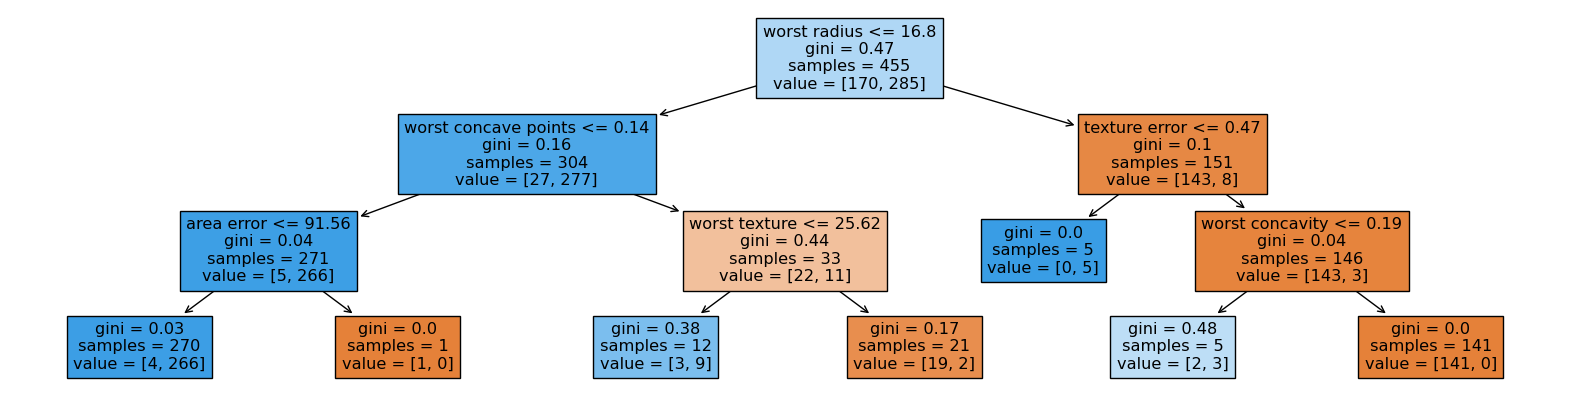

In [ ]:
from sklearn.tree import plot_tree, export_text

fig = plt.figure(figsize=(20,5))
_ = plot_tree(tree_class, feature_names=tree_class.feature_names_in_, filled=True, precision=2)

In [ ]:
# O en formato texto...
text_representation = export_text(tree_class, feature_names = list(tree_class.feature_names_in_))
print(text_representation)

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: 1
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



### b) Máquinas de vector soporte

El segundo algoritmo que hemos visto son las máquinas de vector soporte o SVMs. Como de costumbre, también es muy fácil implementarlos en sklearn.

In [ ]:
# Para regresión. El equivalente para clasificación es SVC
from sklearn.svm import SVR

svm = SVR()
svm.fit(X_reg_train, y_reg_train)

preds_reg = svm.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)

MAE en test: 0.866
MAPE en test: 0.520


(14448, 8)

### c) k vecinos más cercanos

El siguiente es el kNN. Por simplicidad mostraremos solo el caso de clasificación, ya que el de regresión es análogo a los anteriores.

Una de las particularidades del kNN es que requiere que los datos estén normalizados, por tanto es lo primero que debemos hacer.

In [ ]:
# Usamos la normalización min-max (min 0, max 1)
from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()

# Ajustamos con train...
sc.fit(X_clas_train)

# ...y aplicamos la transformación tanto a train como a test
X_train_sc = sc.transform(X_clas_train)
X_test_sc = sc.transform(X_clas_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Por defecto, k = 5
knn = KNeighborsClassifier()

knn.fit(X_train_sc, y_clas_train)

preds_clas = knn.predict(X_test_sc)

precision = precision_score(y_clas_test, preds_clas)
recall = recall_score(y_clas_test, preds_clas)
cm = confusion_matrix(y_clas_test, preds_clas)

print('Precision: %.3f' % precision)
print('Recall %.3f' % recall)
print(cm)

Precision: 0.973
Recall 1.000
[[40  2]
 [ 0 72]]


Como sabemos, este algoritmo es muy propenso a sobreajustar si no se establece el hiperparámetro k de forma correcta. Vamos a cuantificar este efecto pintando la curva de aprendizaje ([aquí](https://scikit-learn.org/stable/auto_examples/model_selection/plot_learning_curve.html#sphx-glr-auto-examples-model-selection-plot-learning-curve-py) más detalles) con respecto a este parámetro. Para ello, entrenaremos varios kNNs escogiendo varios valores para k, y mediremos la AUC tanto en training como en test.

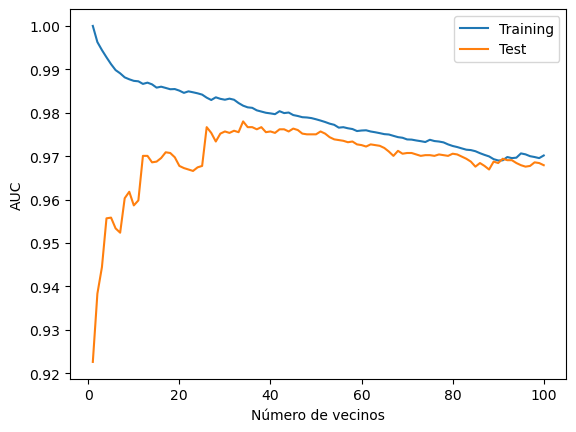

In [ ]:
from sklearn.metrics import roc_auc_score

# Valores posibles de k
K = [i+1 for i in range(100)]

aucs_train = []
aucs_test = []

# Entrenamos cada modelo distinto
for k in K:
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(X_clas_train, y_clas_train)
    preds_train = knn.predict_proba(X_clas_train)[:,1]
    preds_test = knn.predict_proba(X_clas_test)[:,1]
    # Medimos el error
    auc_train = roc_auc_score(y_clas_train, preds_train)
    auc_test = roc_auc_score(y_clas_test, preds_test)

    aucs_train.append(auc_train)
    aucs_test.append(auc_test)

plt.plot(K, aucs_train, label = 'Training')
plt.plot(K, aucs_test, label = 'Test')
plt.legend()
plt.xlabel('Número de vecinos')
plt.ylabel('AUC')
plt.show()

### d) Perceptrón multicapa

El último modelo que vamos a probar es el perceptrón multicapa o MLP, uno de los modelos de red neuronal más sencillos. Aunque sklearn está orientada a machine learning y no a deep learning (para lo que habría que usar otras librerías como Keras, Tensorflow o PyTorch), este modelo está disponible también.

Vamos a usar también el caso de clasificación con los datos normalizados porque, aunque no es un requisito indispensable, las redes suelen funcionar mejor en la práctica de esta forma.

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(random_state = 42, hidden_layer_sizes = [5, 3], learning_rate_init = 0.01)

mlp.fit(X_train_sc, y_clas_train)

preds_clas = mlp.predict(X_test_sc)

precision = precision_score(y_clas_test, preds_clas)
recall = recall_score(y_clas_test, preds_clas)
cm = confusion_matrix(y_clas_test, preds_clas)

print('Precision: %.3f' % precision)
print('Recall %.3f' % recall)
print(cm)

Precision: 0.986
Recall 0.972
[[41  1]
 [ 2 70]]


## 5. Ajuste de hiperparámetros

Una de las claves a la hora de entrenar algoritmos de forma efectiva es la elección de sus hiperparámetros, pues determinan en gran medida su desempeño.

Hay muchas formas de elegir estos hiperparámetros, en esta sección veremos cómo hacerlo utilizando `GridSearchCV`. Esta clase de sklearn iterará por los diferentes valores posibles del parámetro o parámetros a optimizar y utilizará validación cruzada para escoger el mejor modelo posible.

Vamos a utilizar el árbol de decisión para regresión como ejemplo, donde trataremos de elegir la profundidad máxima y el criterio. En este caso, utilizamos el MAE como métrica a optimizar.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Parámetros de búsqueda y posibles valores
grid_parameters = {'criterion': ['squared_error', 'absolute_error'], 'max_depth': [2, 4, 6, 8]}

# Grid search
grid = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid = grid_parameters, cv = 5, scoring = 'neg_mean_absolute_error', verbose = 2)

# Comenzamos el entrenamiento
grid.fit(X_reg_train, y_reg_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=4; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=4; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=4; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=4; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=4; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=6; total time=   0.0s
[CV] END ...............criterion=squared_error, 

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': [2, 4, 6, 8]},
             scoring='neg_mean_absolute_error', verbose=2)

Ahora podemos acceder a los resultados de esta búsqueda y al mejor modelo encontrado.

In [ ]:
print(grid.best_params_)

print(grid.best_score_)

print(grid.best_estimator_)

{'criterion': 'squared_error', 'max_depth': 8}
-0.4504450255591598
DecisionTreeRegressor(max_depth=8, random_state=42)


El mejor modelo es el que tiene una profundidad máxima de 8 y usa como criterio el error absoluto, el cual obtiene un MAE en validación cruzada de 0.44. Ahora ya podemos utilizar estos parámetros para evaluar en el conjunto de test.

Otra ventaja de Sklearn es que puedo utilizar el objeto `grid` directamente como si fuera un modelo, y utilizará el mejor estimador encontrado.

In [ ]:
preds_reg = grid.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)

MAE en test: 0.451
MAPE en test: 0.271


## 6. Selección automática de variables

En los entrenamientos realizados hasta ahora hemos utilizado todas las variables disponibles en los conjuntos de datos, sin analizar si son significativas o no. En esta sección vamos a ver algunos métodos de sklearn para realizar una selección automática de las variables. En [este](https://scikit-learn.org/stable/modules/feature_selection.html) enlace se pueden ver todos los métodos disponibles.

Vamos a utilizar técnicas que seleccionan las variables más importantes en base a diferentes test estadísticos: el test F para el caso de regresión y el test Chi2 para clasificación. Con el método `SelectKBest` seleccionamos las K mejores variables.

In [ ]:
# Para regresión
from sklearn.feature_selection import SelectKBest, chi2, f_regression

# Seleccionamos las 5 mejores variables
selector = SelectKBest(f_regression, k=5)

X_reg_select = selector.fit_transform(X_reg_train, y_reg_train)

print(selector.get_feature_names_out())

for var, value in zip(selector.feature_names_in_, selector.scores_):
    print('Variable %s: %.4f' % (var, value))

['MedInc' 'HouseAge' 'AveRooms' 'Latitude' 'Longitude']
Variable MedInc: 13000.0948
Variable HouseAge: 165.8850
Variable AveRooms: 342.1442
Variable AveBedrms: 33.9979
Variable Population: 8.5466
Variable AveOccup: 6.3491
Variable Latitude: 295.2720
Variable Longitude: 35.2640


In [ ]:
# Para clasificación
selector = SelectKBest(chi2, k=5)

X_clas_train_select = selector.fit_transform(X_clas_train, y_clas_train)

logreg = LogisticRegression(random_state=42, solver = 'liblinear')
logreg.fit(X_clas_train_select, y_clas_train)

X_clas_test_select = selector.transform(X_clas_test)
preds_clas = logreg.predict(X_clas_test_select)

precision = precision_score(y_clas_test, preds_clas)
recall = recall_score(y_clas_test, preds_clas)
cm = confusion_matrix(y_clas_test, preds_clas)

print('Precision: %.3f' % precision)
print('Recall %.3f' % recall)
print(cm)

Precision: 0.933
Recall 0.972
[[37  5]
 [ 2 70]]


En este caso la selección de variables no aporta gran cosa, ya que el dataset es pequeño y es posible resolver la tarea incluso usando variables poco significativas. Sin embargo, en datasets reales con decenas o cientos de variables, estas técnicas pueden ser útiles para depurar la información de entrada.

## 7. Combinación de modelos

En ocasiones combinar diferentes modelos, especialmente si son diferentes, puede mejorar el resultado de cada uno de ellos. Existen muchos métodos para combinar modelos ([aquí](https://scikit-learn.org/stable/modules/ensemble.html#voting-classifier) más información), y en este sección veremos algunos ejemplos de ello.

Uno de los algoritmos de ensembling más famoso es el Random Forest, que consiste en entrenar muchos árboles de decisión diferentes y combinar sus resultados.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Un único árbol
tree = DecisionTreeRegressor(random_state = 42)

tree.fit(X_reg_train, y_reg_train)

preds_reg = tree.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('Árbol de decisión')
print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)
print('')

# Random forest con 10 estimadores
rf = RandomForestRegressor(n_estimators = 10, random_state = 42)

rf.fit(X_reg_train, y_reg_train)

preds_reg = rf.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('Random forest')
print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)

Árbol de decisión
MAE en test: 0.469
MAPE en test: 0.259

Random forest
MAE en test: 0.352
MAPE en test: 0.201


También las técnicas de boosting están disponibles en sklearn, destacando el GradientBoosting y el AdaBoost.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# Un único árbol
gbr = GradientBoostingRegressor(random_state = 42)

gbr.fit(X_reg_train, y_reg_train)

preds_reg = gbr.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('Gradient boosting')
print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)

Gradient boosting
MAE en test: 0.371
MAPE en test: 0.215


La última técnica de ensembling de modelos que veremos es la de combinar las predicciones de varios modelos distintos. Con ello, se consiguen unas estimaciones más robustas ya que los fallos de un modelo se pueden compensar con otro.

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC

# Creamos 2 modelos independientes
model1 = SVC(random_state = 42, kernel = 'poly', C = 10.0, probability = True)
model2 = KNeighborsClassifier(n_neighbors = 2)

model1.fit(X_train_sc, y_clas_train)
model2.fit(X_train_sc, y_clas_train)

print('Accuracy SVC: %.3f' % model1.score(X_test_sc, y_clas_test))
print('Accuracy kNN: %.3f' % model2.score(X_test_sc, y_clas_test))

vc = VotingClassifier(estimators = [('svc', model1), ('knn', model2)], voting = 'soft')
vc.fit(X_train_sc, y_clas_train)

print('Accuracy modelo combinado: %.3f' % vc.score(X_test_sc, y_clas_test))

Accuracy SVC: 0.956
Accuracy kNN: 0.939
Accuracy modelo combinado: 0.974


## 8. Poniendo todo junto...

Finalmente, vamos a juntar todo lo que hemos aprendido. Hemos visto cómo entrenar modelos, elegir hiperparámetros, normalizar datos, seleccionar variables... ¿Pero se puede hacer todo junto? Lo respuesta es sí, gracias a las `Pipelines`. Las pipelines permiten concatenar diferentes pasos a la hora de entrenar, de forma que todo queda condensado en un único objeto. Esto es útil por ejemplo a la hora de desplegar modelos y reproducir los mismos pasos que en entrenamiento.

Para ilustrarlo vamos a volver al problema de regresión utilizando el MLP. Los pasos de nuestra pipeline serán los siguientes:
 - Normalizar los datos
 - Seleccionar las variables más significativas
 - Entrenar el MLP, optimizando sus parámetros con GridSearchCV

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

pipeline = Pipeline(steps = [
    ('sc', MinMaxScaler()),
    ('selector', SelectKBest(f_regression)),
    ('model', MLPRegressor(random_state = 42, solver = 'adam', learning_rate_init = 0.01))
])

Ahora definimos la malla de búsqueda. Además de elegir los parámetros del MLP, también podemos optimizar el número de variables a elegir.

In [ ]:
param_grid = {
    'selector__k': [2, 4, 8],
    'model__hidden_layer_sizes': [(5,), (5, 3)],
    'model__activation': ['tanh', 'relu'],
}

grid = GridSearchCV(pipeline, param_grid = param_grid, cv = 3, scoring = 'neg_mean_absolute_error', verbose = 1)

grid.fit(X_reg_train, y_reg_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


/Users/jajimer/miniconda3/envs/uax/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/jajimer/miniconda3/envs/uax/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/jajimer/miniconda3/envs/uax/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('sc', MinMaxScaler()),
                                       ('selector',
                                        SelectKBest(score_func=<function f_regression at 0x156415820>)),
                                       ('model',
                                        MLPRegressor(learning_rate_init=0.01,
                                                     random_state=42))]),
             param_grid={'model__activation': ['tanh', 'relu'],
                         'model__hidden_layer_sizes': [(5,), (5, 3)],
                         'selector__k': [2, 4, 8]},
             scoring='neg_mean_absolute_error', verbose=1)

In [ ]:
print(grid.best_params_)

print(grid.best_score_)

print(grid.best_estimator_)

{'model__activation': 'tanh', 'model__hidden_layer_sizes': (5, 3), 'selector__k': 8}
-0.44082540232447015
Pipeline(steps=[('sc', MinMaxScaler()),
                ('selector',
                 SelectKBest(k=8,
                             score_func=<function f_regression at 0x156415820>)),
                ('model',
                 MLPRegressor(activation='tanh', hidden_layer_sizes=(5, 3),
                              learning_rate_init=0.01, random_state=42))])


In [ ]:
preds_reg = grid.predict(X_reg_test)

mae_test = mean_absolute_error(y_reg_test, preds_reg)
mape_test = mean_absolute_percentage_error(y_reg_test, preds_reg)

print('MAE en test: %.3f' % mae_test)
print('MAPE en test: %.3f' % mape_test)

MAE en test: 0.433
MAPE en test: 0.251


In [ ]:
# Para terminar, guardamos el modelo...
from joblib import dump

grid.model_version = 'v1'

dump(grid, 'modelo_final.joblib')

['modelo_final.joblib']

## Conclusiones

En este cuaderno hemos implementado y entrenado diferentes algoritmos de Machine Learning utilizando la librería scikit-learn. Hemos visto que gracias a su interfaz unificada es sencillo realizar diferentes experimentos cambiando tan solo unas pocas líneas de código.

Conviene destacar que los datasets que hemos utilizado en este ejemplo son de "juguete", y ha sido posible resolver los problemas incluso con modelos lineales. Además, no ha sido necesario procesar los datos ni crear nuevas variables explicativas. Cuando usemos conjuntos de datos más complejos este proceso será normalmente mucho más complicado y se requerirá mayor análisis, experimentación e interpretación de los resultados para conseguir algoritmos que se puedan utilizar en el mundo real.

## Ejercicios propuestos

- A la vista de todos los experimentos realizados... ¿Cuál sería su modelo "ganador" para cada uno de los dos problemas? ¿Por qué?
- Considere ahora el conjunto de datos que se puede descargar utilizando la siguiente función: `datasets.load_wine`. En este caso se trata de un problema multi-clase, donde se pide clasificar diferentes tipos de vino en 3 categorías (0, 1, 2). Divida este dataset en train y test, entrene un algoritmo de clasificación y evalúelo en el conjunto de test. Tenga en cuenta las modificaciones en el código necesarias para el caso multi-clase. Pista: las funciones de sklearn que hemos utilizado tienen varios parámetros disponibles, y su documentación es muy útil... :)